# Nội dung bài LAB 

1. Phương pháp sử dụng các thư viện chẩn để thiết kế bộ lọc FIR 
    * a. Sử dụng thư viên `numpy` để lấy các giá trị cửa sổ
    * b. Sử dụng thư viên `scipy` để lấy các giá trị cửa sổ
    * c. Sử dụng hàm `firwin` và `lfilter` để thực hiện bộ lọc FIR


# 1. Phương pháp sử dụng các thư viện chuẩn để thiết kế bộ lọc FIR có cửa sổ


## 1) Nguyên lý gốc (DSP “cổ điển”)

Với tín hiệu rời rạc:

* Sampling rate: ( f_s ) (Hz)
* Nyquist frequency:
  $
  f_N = \frac{f_s}{2}
  $

👉 **Tần số chuẩn hoá (normalized cutoff)** là:

$$
\boxed{
f_{\text{norm}} = \frac{f_c}{f_N} = \frac{2 f_c}{f_s}
}
$$

Trong đó:

* ( f_c ) = cutoff frequency (Hz)
* ( f_{\text{norm}} \in (0, 1) )

---

## 2) Ví dụ cụ thể (rất quan trọng)

Giả sử:

* ( f_s = 1000 ) Hz
* ( f_c = 100 ) Hz

Nyquist:
$
f_N = 500 \text{ Hz}
$

Chuẩn hoá:

```python
fc = 100
fs = 1000
f_norm = fc / (fs/2)
print(f_norm)   # 0.2
```

👉 **0.2 chính là con số bạn hay thấy trong `firwin()`**

---

## 3) Dùng trong `firwin()` — 2 cách (đừng trộn lẫn)

### ✅ Cách A — **Chuẩn hoá thủ công (kiểu cũ)**

```python
b = firwin(N, cutoff=0.2)
```

Điều kiện:

* KHÔNG truyền `fs`
* `cutoff` ∈ (0, 1) **so với Nyquist**

---

### ✅ Cách B — **Dùng Hz thật (khuyên dùng)**

```python
b = firwin(N, cutoff=100, fs=1000)
```

SciPy tự làm:
$
f_{\text{norm}} = \frac{2 f_c}{f_s}
$

✔ rõ ràng
✔ ít lỗi
✔ đúng kiểu kỹ sư làm việc

---

## 4) Band-pass thì sao?

Công thức **y chang**, chỉ áp dụng cho từng biên:

```python
low = 200
high = 350
fs = 1000

cutoff_norm = [low/(fs/2), high/(fs/2)]
# [0.4, 0.7]
```

Hoặc gọn hơn:

```python
b = firwin(N, [200, 350], fs=1000, pass_zero=False)
```

---

## 5) Nhầm lẫn phổ biến (rất hay gặp)

❌ **Sai**

```python
cutoff = fc / fs
```

→ Sai vì **chuẩn hoá theo Nyquist, không phải fs**

❌ **Sai**

```python
cutoff = 0.5
```

→ 0.5 nghĩa là **fs/4**, không phải fs/2

---

## 6) Bảng nhớ nhanh (cheat sheet)

| Ý nghĩa       | Công thức          |
| ------------- | ------------------ |
| Nyquist       | $( f_s / 2 )$        |
| Chuẩn hoá     | $( 2f_c / f_s )$     |
| firwin (Hz)   | `cutoff=fc, fs=fs` |
| firwin (norm) | `cutoff=fc/(fs/2)` |

---

### Kết luận (nói thẳng)

> **Chuẩn hoá cutoff = chia cho Nyquist, không phải sampling rate.**
> Nếu không muốn nghĩ → **luôn truyền `fs=` và dùng Hz thật.**

Nếu bạn muốn, mình có thể:

* nối luôn sang **trục ω (rad/sample)** để khớp công thức DTFT
* hoặc chỉ ra **vì sao Nyquist lại là mốc 1.0 trong DSP**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter, firwin

## 1. Sử dụng hàm firwin trong scipy.signal - Cach 1

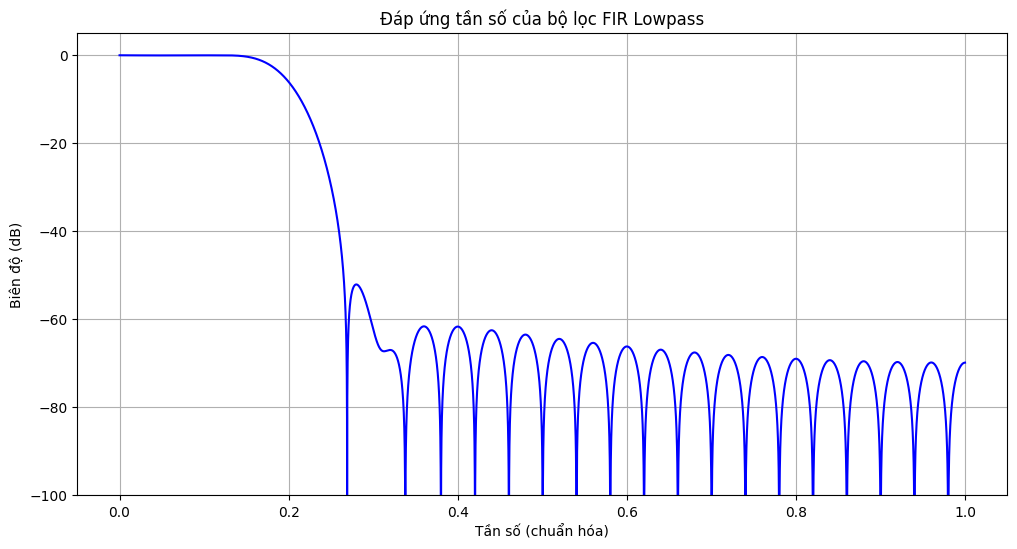

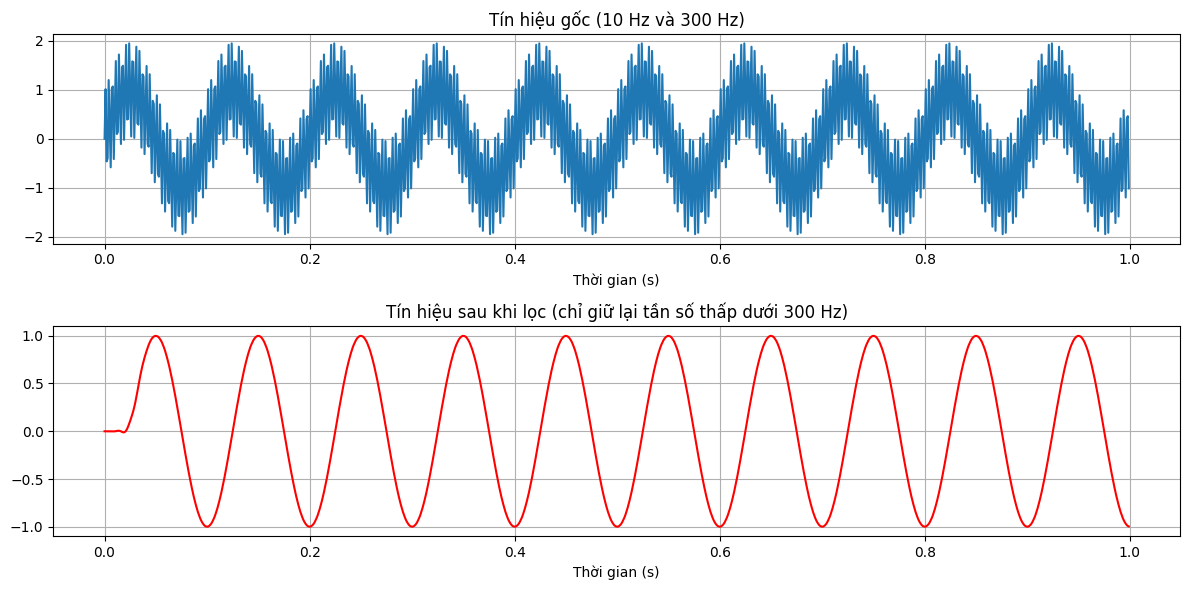

In [2]:

# Thông số bộ lọc
N = 51  # Số lượng taps (độ dài bộ lọc)
cutoff_freq = 0.2  # Tần số cắt chuẩn hóa (tần số cắt / Nyquist, từ 0 đến 0.5)
window_type = 'hamming'  # Loại cửa sổ, có thể thay bằng 'hanning', 'blackman',...

# Tạo bộ lọc FIR lowpass sử dụng firwin
b = firwin(N, cutoff_freq, pass_zero=True, window=window_type)

# Hiển thị đáp ứng tần số của bộ lọc
w, h = freqz(b, worN=8000)
plt.figure(figsize=(12, 6))
plt.plot(w / np.pi, 20 * np.log10(abs(h)), color='blue')
plt.title('Đáp ứng tần số của bộ lọc FIR Lowpass')
plt.xlabel('Tần số (chuẩn hóa)')
plt.ylabel('Biên độ (dB)')
plt.grid()
plt.ylim(-100, 5)
plt.show()

# Tạo tín hiệu mẫu (kết hợp tần số thấp và cao)
sampling_rate = 1000  # Tần số lấy mẫu (Hz)
t = np.linspace(0, 1, sampling_rate, endpoint=False)
x = np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 300 * t)  # Tần số 10 Hz và 300 Hz

# Lọc tín hiệu bằng bộ lọc FIR lowpass
y = lfilter(b, 1.0, x)

# Hiển thị tín hiệu trước và sau khi lọc
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(t, x)
plt.title('Tín hiệu gốc (10 Hz và 300 Hz)')
plt.xlabel('Thời gian (s)')
plt.grid()
plt.subplot(2, 1, 2)
plt.plot(t, y, color='red')
plt.title('Tín hiệu sau khi lọc (chỉ giữ lại tần số thấp dưới 300 Hz)')
plt.xlabel('Thời gian (s)')
plt.grid()
plt.tight_layout()
plt.show()

### Cach 2

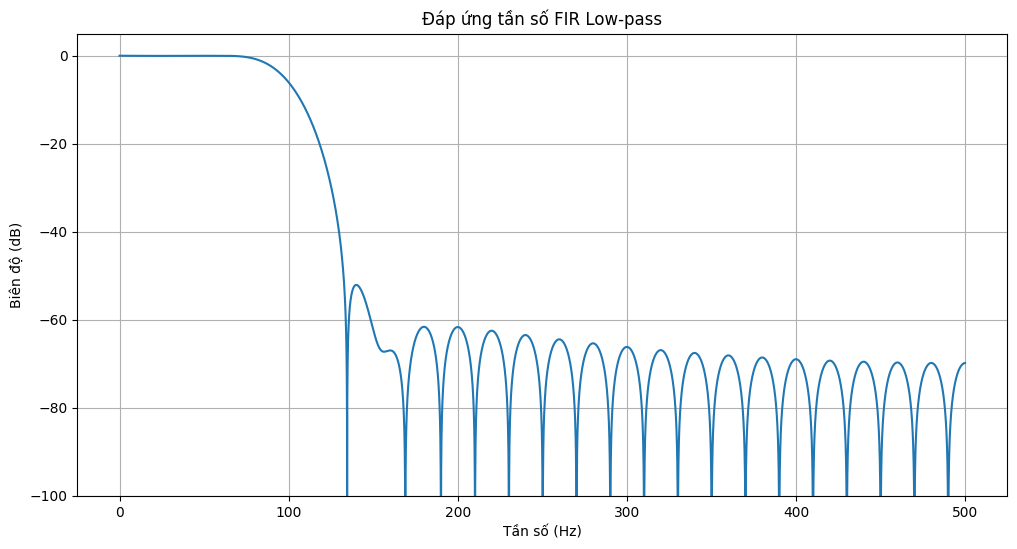

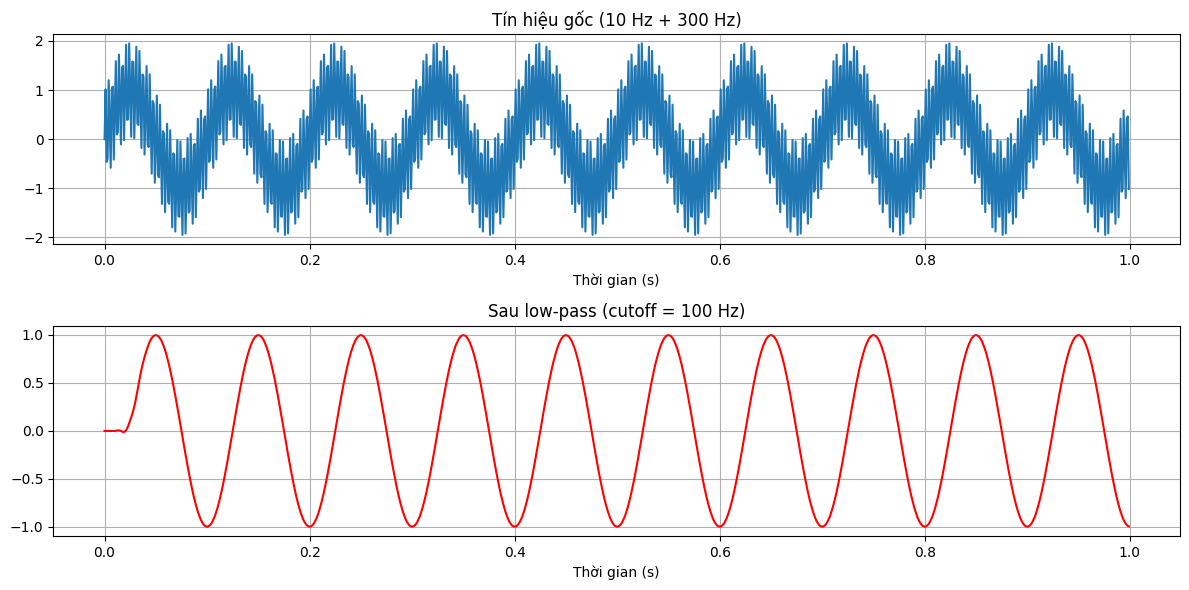

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter, firwin

# -----------------------------
# Thông số bộ lọc
# -----------------------------
N = 51
sampling_rate = 1000      # Hz
cutoff_freq_hz = 100      # Hz (thay cho 0.2 normalized)
window_type = "hamming"

# FIR low-pass (dùng Hz thật)
b = firwin(
    N,
    cutoff=cutoff_freq_hz,
    pass_zero=True,
    window=window_type,
    fs=sampling_rate
)

# -----------------------------
# Đáp ứng tần số
# -----------------------------
w, h = freqz(b, worN=8000, fs=sampling_rate)

plt.figure(figsize=(12, 6))
plt.plot(w, 20 * np.log10(np.maximum(np.abs(h), 1e-12)))
plt.title("Đáp ứng tần số FIR Low-pass")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ (dB)")
plt.grid(True)
plt.ylim(-100, 5)
plt.show()

# -----------------------------
# Tín hiệu mẫu
# -----------------------------
t = np.linspace(0, 1, sampling_rate, endpoint=False)
x = np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 300 * t)

# Lọc tín hiệu
y = lfilter(b, 1.0, x)

# -----------------------------
# Plot tín hiệu
# -----------------------------
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(t, x)
plt.title("Tín hiệu gốc (10 Hz + 300 Hz)")
plt.xlabel("Thời gian (s)")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, y, color="red")
plt.title("Sau low-pass (cutoff = 100 Hz)")
plt.xlabel("Thời gian (s)")
plt.grid(True)

plt.tight_layout()
plt.show()

## Changes N 

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz, lfilter

from ipywidgets import IntSlider, VBox, HTML, interactive_output

# -----------------------------
# Fixed settings
# -----------------------------
fs = 1000            # sampling rate (Hz)
cutoff_hz = 100      # cutoff frequency (Hz)
window_type = "hamming"

# Test signal: 10 Hz + 300 Hz
t = np.linspace(0, 1, fs, endpoint=False)
x = np.sin(2*np.pi*10*t) + np.sin(2*np.pi*300*t)

def update(N):
    # Enforce odd N (typical for linear-phase FIR lowpass)
    if N % 2 == 0:
        N += 1

    # Design FIR low-pass using Hz + fs (recommended)
    b = firwin(N, cutoff=cutoff_hz, window=window_type, fs=fs, pass_zero=True)

    # Filter
    y = lfilter(b, 1.0, x)

    # Display alignment: compensate approximate group delay (N-1)/2 samples
    delay = (N - 1) // 2
    y_aligned = np.full_like(y, np.nan, dtype=float)
    if delay < len(y):
        y_aligned[:-delay] = y[delay:]

    # -------- Plot 1: Frequency response (Hz) --------
    w, h = freqz(b, worN=4096, fs=fs)
    mag_db = 20*np.log10(np.maximum(np.abs(h), 1e-12))

    plt.figure(figsize=(11, 4))
    plt.plot(w, mag_db)
    plt.title(f"FIR Low-pass Frequency Response | N={N}, cutoff={cutoff_hz} Hz")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    plt.ylim(-120, 5)
    plt.show()

    # -------- Plot 2: Time domain --------
    plt.figure(figsize=(11, 4))
    plt.plot(t, x, label="Original")
    plt.plot(t, y_aligned, label=f"Filtered (display aligned), delay≈{delay} samples")
    plt.title("Signal vs Filtered (delay-compensated for display)")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.legend()
    plt.show()

# Slider: step=2 keeps it odd
N_slider = IntSlider(value=51, min=11, max=301, step=2, description="N (taps)", continuous_update=False)

info = HTML("<b>Rule of thumb:</b> bigger N → sharper transition & better stopband, but more delay (~(N−1)/2 samples).")

ui = VBox([info, N_slider])
out = interactive_output(update, {"N": N_slider})

VBox([ui, out])

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz, lfilter
from ipywidgets import IntSlider, FloatSlider, VBox, HTML, interactive_output

# -----------------------------
# Fixed parameters
# -----------------------------
fs = 1000
window_type = "hamming"

# Test signal: low + high frequency
t = np.linspace(0, 1, fs, endpoint=False)
x = np.sin(2*np.pi*10*t) + np.sin(2*np.pi*300*t)

def update(N, cutoff_hz):
    # Enforce odd N (linear-phase FIR)
    if N % 2 == 0:
        N += 1

    # Safety: cutoff < Nyquist
    cutoff_hz = min(cutoff_hz, fs/2 - 1)

    # FIR low-pass design (Hz-based)
    b = firwin(
        N,
        cutoff=cutoff_hz,
        window=window_type,
        fs=fs,
        pass_zero=True
    )

    # Filtering
    y = lfilter(b, 1.0, x)

    # Group delay compensation (display only)
    delay = (N - 1) // 2
    y_disp = np.full_like(y, np.nan)
    if delay < len(y):
        y_disp[:-delay] = y[delay:]

    # -----------------------------
    # Frequency response
    # -----------------------------
    w, h = freqz(b, worN=4096, fs=fs)
    mag_db = 20*np.log10(np.maximum(np.abs(h), 1e-12))

    plt.figure(figsize=(11, 4))
    plt.plot(w, mag_db)
    plt.axvline(cutoff_hz, color="r", linestyle="--", label="Cutoff")
    plt.title(f"FIR Low-pass | N={N}, cutoff={cutoff_hz:.1f} Hz")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    plt.ylim(-120, 5)
    plt.legend()
    plt.show()

    # -----------------------------
    # Time domain
    # -----------------------------
    plt.figure(figsize=(11, 4))
    plt.plot(t, x, label="Original")
    plt.plot(t, y_disp, label="Filtered (delay-aligned)")
    plt.title("Signal vs Filtered")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.legend()
    plt.show()

# -----------------------------
# Sliders
# -----------------------------
N_slider = IntSlider(
    value=51, min=11, max=301, step=2,
    description="N (taps)", continuous_update=False
)

cutoff_slider = FloatSlider(
    value=100.0, min=10.0, max=450.0, step=5.0,
    description="Cutoff (Hz)", continuous_update=False
)

info = HTML(
    "<b>Explore:</b><br>"
    "• Increase <b>N</b> → sharper transition, more delay<br>"
    "• Increase <b>cutoff</b> → more high-frequency content passes"
)

ui = VBox([info, N_slider, cutoff_slider])
out = interactive_output(update, {"N": N_slider, "cutoff_hz": cutoff_slider})

VBox([ui, out])